# U02.E04 · Clasificador visual con CNN (Fashion-MNIST)

Roque Alexis Ventura Vallejo · 100805873

Este notebook **no reentrena**: usa los artefactos de `scripts/train_cv.py --epochs 8` (y del experimento `--epochs 30 --run-name epochs30`), recarga los modelos guardados y verifica las métricas sobre el conjunto de prueba.

In [1]:
import json
from pathlib import Path

import numpy as np
import tensorflow as tf
from IPython.display import Image, display
from sklearn.metrics import f1_score

from inf8239_u02_cv.data import CLASS_NAMES, audit_splits, load_splits
from inf8239_u02_cv.evaluation import measure_inference, top_confusions

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
REPORTS, MODELS = ROOT / 'reports', ROOT / 'models'
print('TensorFlow', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0 | GPU: []


## 1. Auditoría y partición
Partición fija: las últimas 6,000 imágenes de entrenamiento son validación; la prueba oficial (10,000) no se toca hasta el final.

In [2]:
(x_train, y_train), (x_valid, y_valid), (x_test, y_test) = load_splits(tf)
audit = audit_splits({'train': (x_train, y_train), 'valid': (x_valid, y_valid), 'test': (x_test, y_test)})
for name, info in audit['splits'].items():
    print(f"{name:5s} forma={info['shape']} rango=[{info['min']}, {info['max']}] duplicados={info['duplicates_within']}")
    print('      clases:', info['class_counts'])
print('Imágenes compartidas entre particiones:', audit['overlap'])

train forma=[54000, 28, 28, 1] rango=[0.0, 1.0] duplicados=0
      clases: [5370, 5416, 5398, 5395, 5367, 5409, 5435, 5445, 5384, 5381]
valid forma=[6000, 28, 28, 1] rango=[0.0, 1.0] duplicados=0
      clases: [630, 584, 602, 605, 633, 591, 565, 555, 616, 619]
test  forma=[10000, 28, 28, 1] rango=[0.0, 1.0] duplicados=0
      clases: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
Imágenes compartidas entre particiones: {'train-valid': 0, 'train-test': 0, 'valid-test': 0}


## 2. Baseline denso vs. CNN (misma partición, 8 épocas)

In [3]:
metrics = json.loads((REPORTS / 'cv_metrics.json').read_text())
long_run = json.loads((REPORTS / 'epochs30' / 'cv_metrics.json').read_text())
print(f"{'modelo':16s}{'F1-macro':>9s}{'acc':>7s}{'params':>8s}{'KB':>7s}{'train s':>9s}{'ms/img':>8s}")
for label, source in (('8 ép.', metrics), ('30 ép.', long_run)):
    for name in ('dense', 'cnn'):
        m = source[name]
        print(f"{name + ' ' + label:16s}{m['f1_macro']:9.3f}{m['accuracy']:7.3f}{m['parameters']:8d}{m['model_file_kb']:7.0f}"
              f"{m['train_seconds']:9.1f}{m['inference_repeated']['median_ms_per_image']:8.3f}")

modelo           F1-macro    acc  params     KB  train s  ms/img
dense 8 ép.         0.864  0.865   50890    619      5.8   0.012
cnn 8 ép.           0.789  0.793   19466    262     66.9   0.055
dense 30 ép.        0.875  0.876   50890    619     16.4   0.012
cnn 30 ép.          0.848  0.851   19466    262    240.5   0.054


### Verificación: el modelo guardado reproduce la métrica del reporte

In [4]:
cnn = tf.keras.models.load_model(MODELS / 'best_cnn.keras')
dense = tf.keras.models.load_model(MODELS / 'dense_baseline.keras')
for name, model in (('dense', dense), ('cnn', cnn)):
    probabilities = model.predict(x_test, verbose=0)
    assert np.isfinite(probabilities).all() and np.allclose(probabilities.sum(axis=1), 1, atol=1e-4)
    f1 = f1_score(y_test, probabilities.argmax(axis=1), average='macro')
    print(f'{name}: F1 recalculado={f1:.4f} | reporte={metrics[name]["f1_macro"]:.4f}')

dense: F1 recalculado=0.8637 | reporte=0.8637


cnn: F1 recalculado=0.7890 | reporte=0.7890


## 3. Curvas de entrenamiento y validación

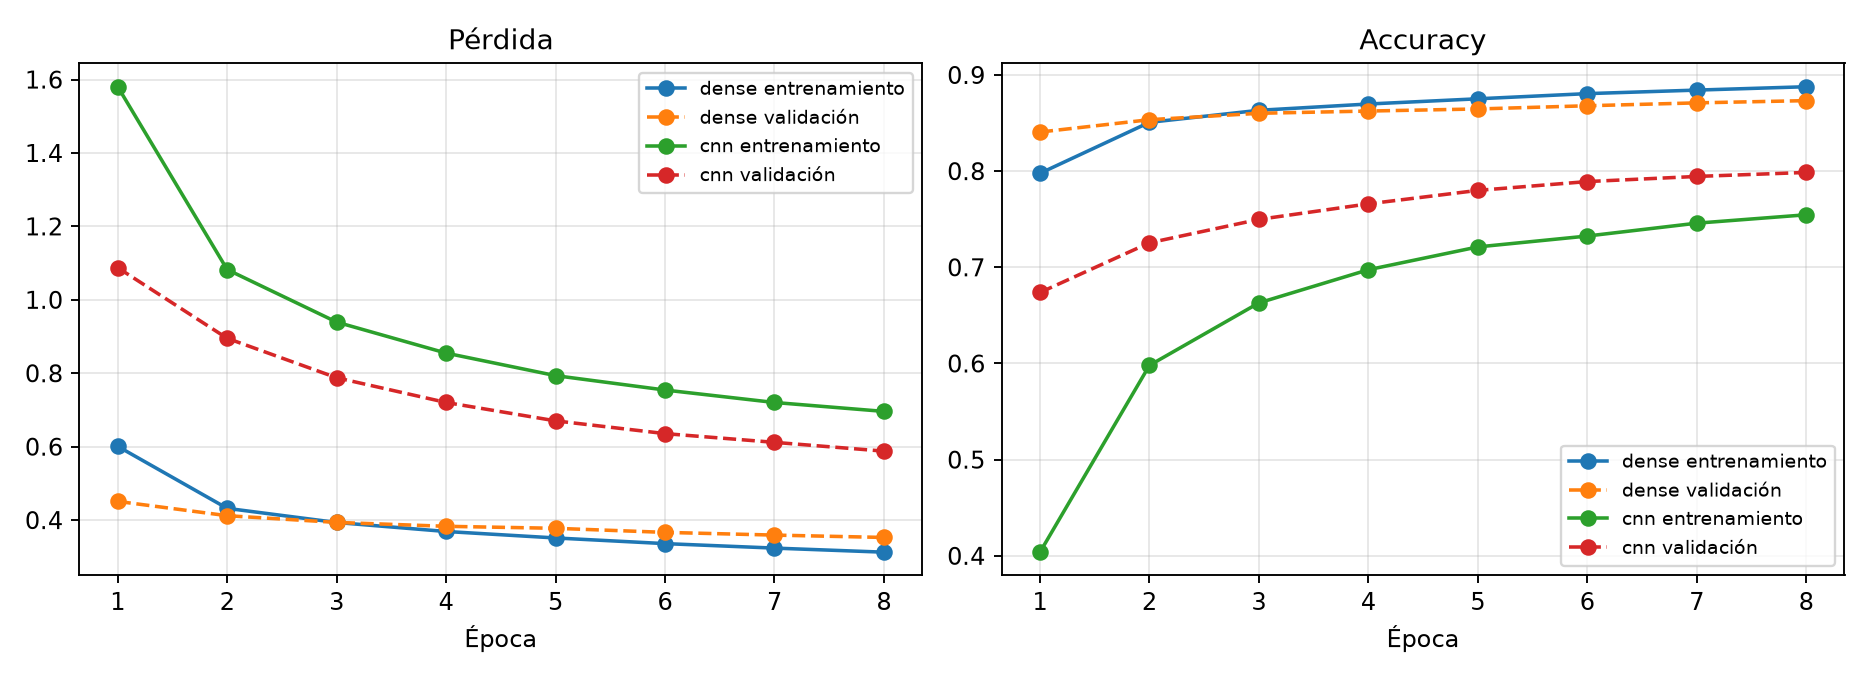

In [5]:
display(Image(REPORTS / 'training_curves.png', width=900))

Lectura: la CNN tiene validación por encima de entrenamiento (Dropout solo actúa al entrenar) y ambas pérdidas siguen bajando en la época 8: **subajuste**, no sobreajuste. El baseline denso converge rápido y su brecha es pequeña.

## 4. Métricas y errores por clase

clase        F1 dense  F1 cnn recall cnn
T-shirt/top     0.818   0.717      0.805
Trouser         0.974   0.959      0.929
Pullover        0.754   0.675      0.649
Dress           0.863   0.796      0.845
Coat            0.780   0.664      0.670
Sandal          0.951   0.916      0.883
Shirt           0.651   0.422      0.364
Sneaker         0.935   0.901      0.953
Bag             0.960   0.926      0.937
Ankle boot      0.951   0.915      0.896


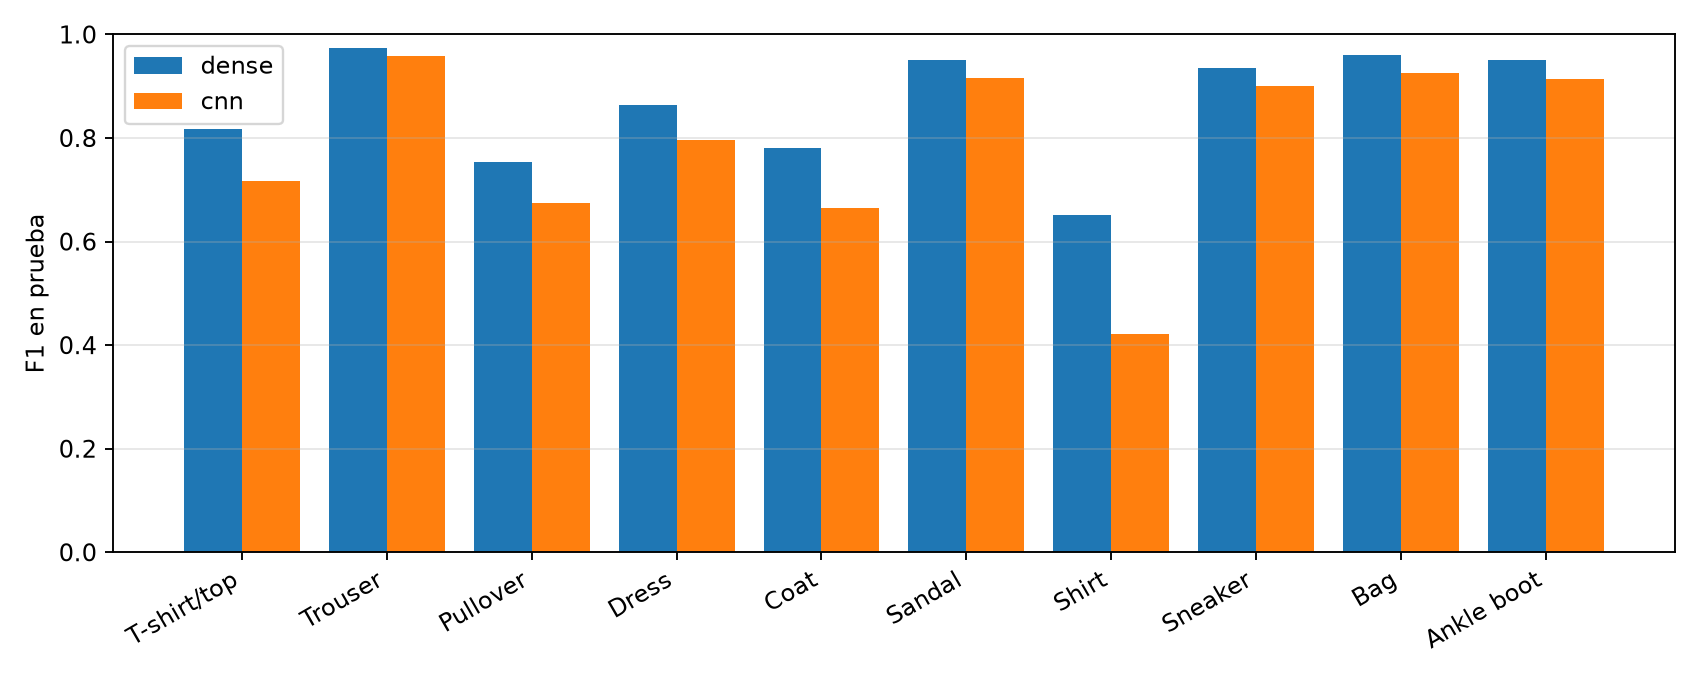

In [6]:
reports = json.loads((REPORTS / 'classification_reports.json').read_text())
print(f"{'clase':12s}{'F1 dense':>9s}{'F1 cnn':>8s}{'recall cnn':>11s}")
for label in CLASS_NAMES:
    print(f"{label:12s}{reports['dense'][label]['f1-score']:9.3f}{reports['cnn'][label]['f1-score']:8.3f}{reports['cnn'][label]['recall']:11.3f}")
display(Image(REPORTS / 'per_class_f1.png', width=850))

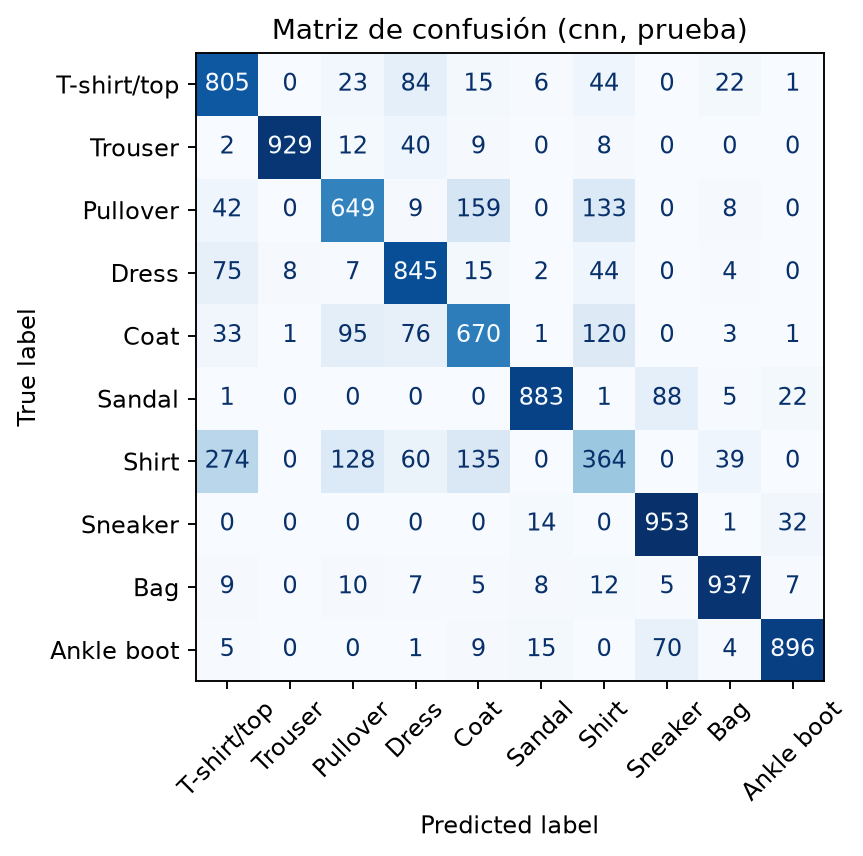

Pares más confundidos (CNN):
  Shirt -> T-shirt/top: 274
  Pullover -> Coat: 159
  Shirt -> Coat: 135
  Pullover -> Shirt: 133
  Shirt -> Pullover: 128


In [7]:
display(Image(REPORTS / 'confusion_cnn.png', width=520))
print('Pares más confundidos (CNN):')
for pair in metrics['cnn']['top_confusions']:
    print(f"  {pair['true']} -> {pair['pred']}: {pair['count']}")

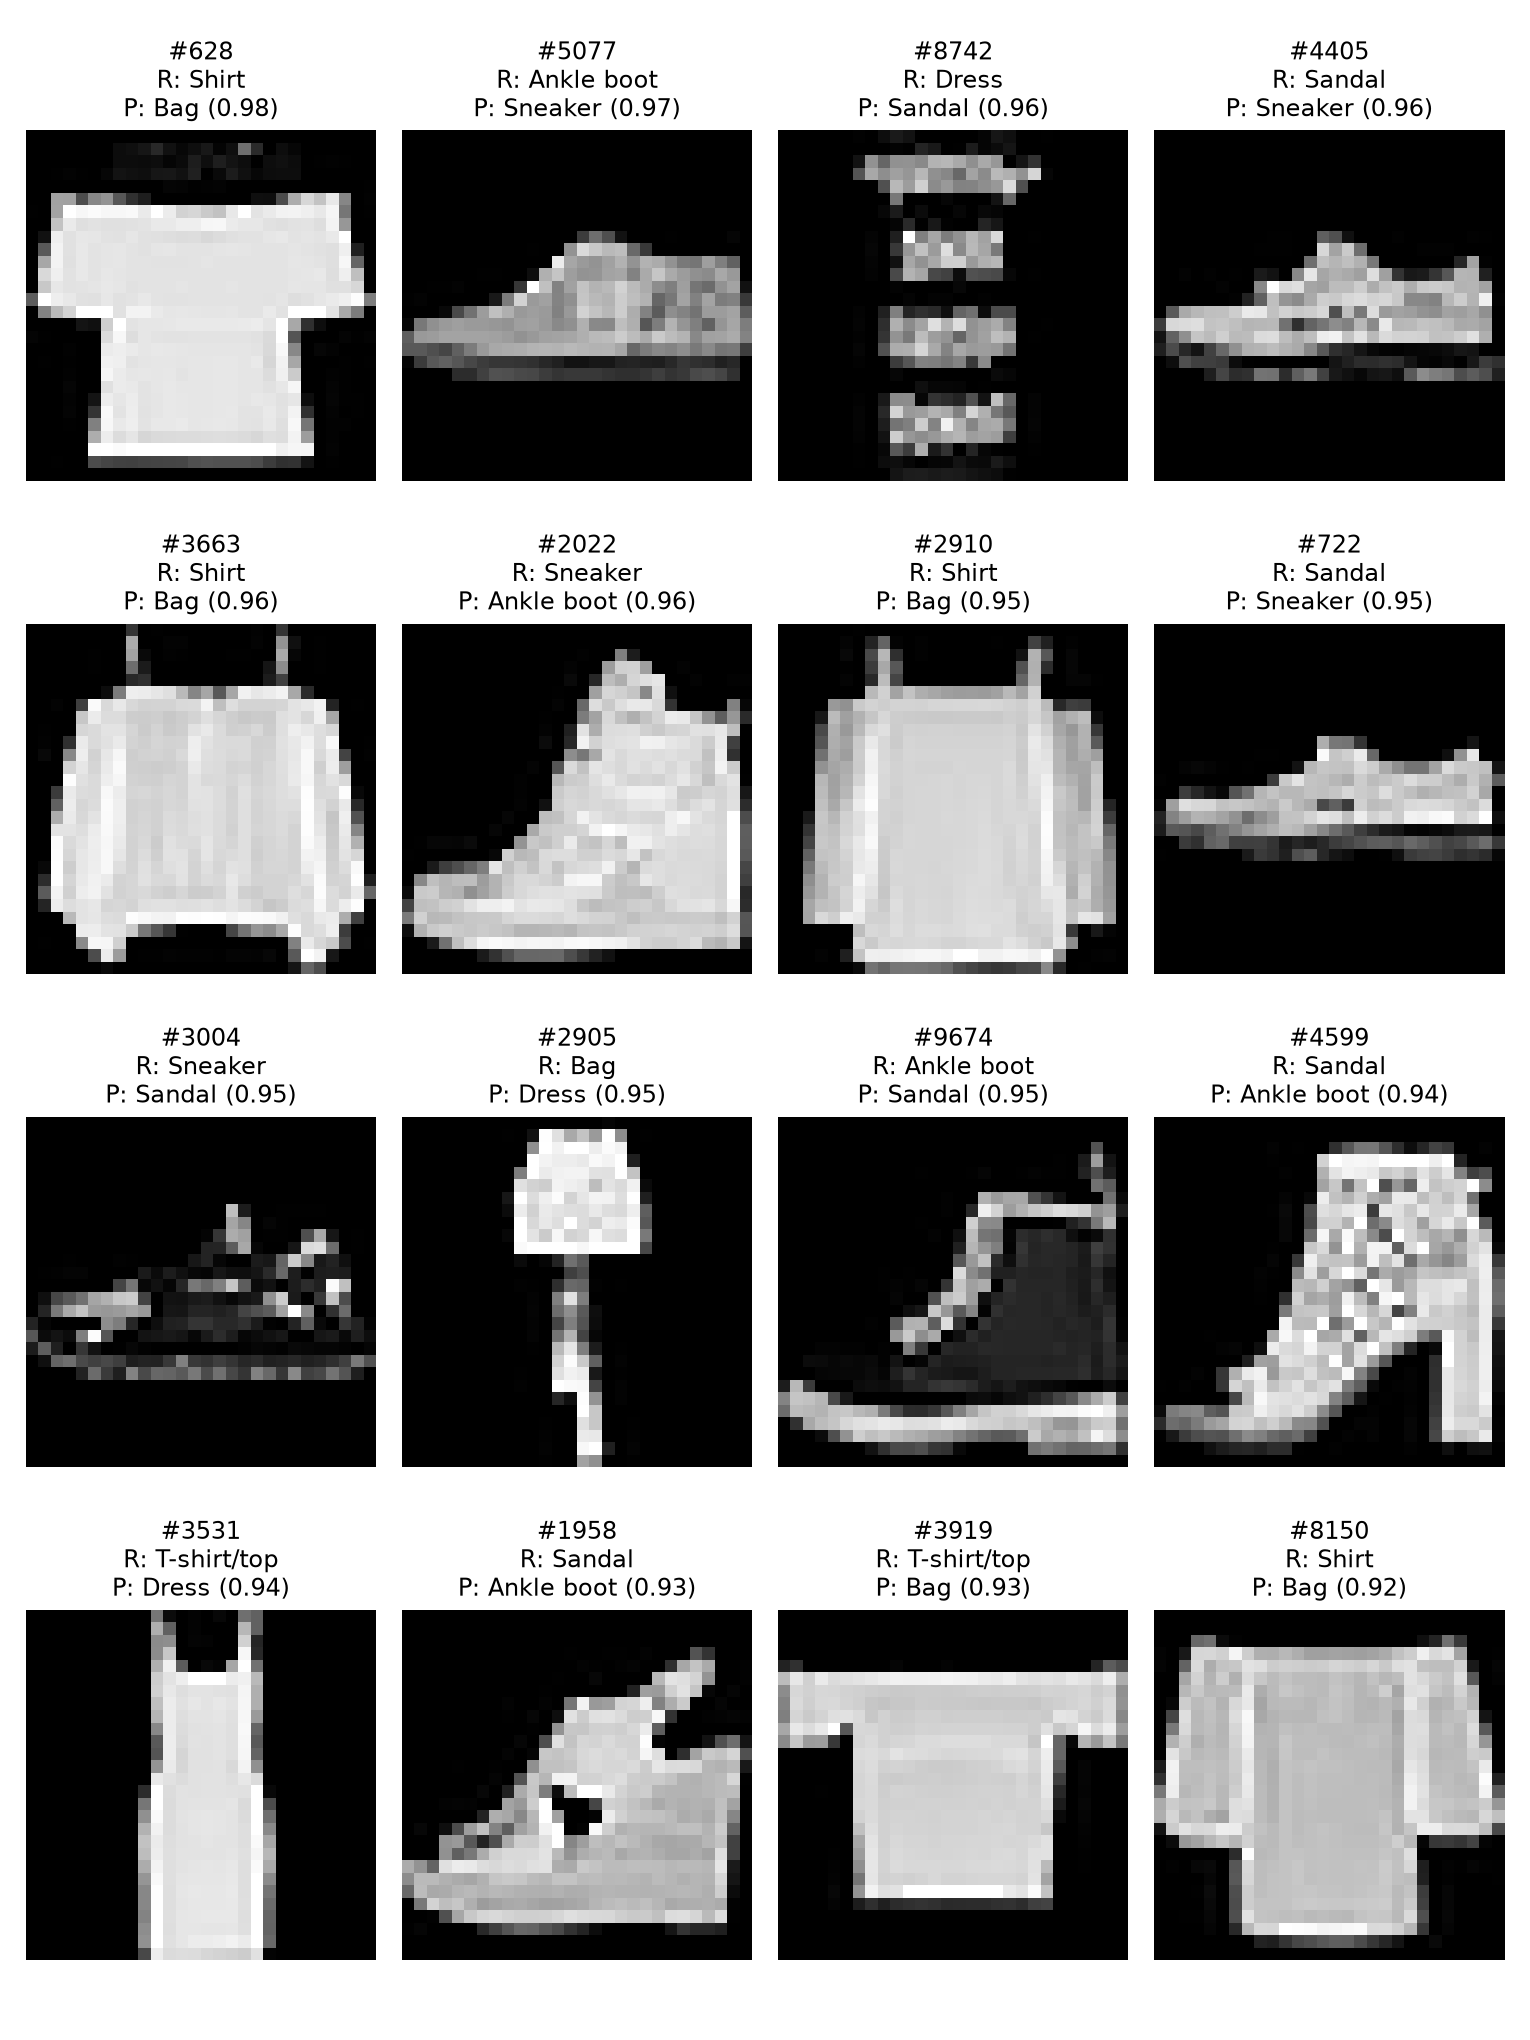

In [8]:
display(Image(REPORTS / 'cnn_errors.png', width=700))

Los 16 errores con mayor confianza: varias camisas anchas o con tirantes se predicen como *Bag*; sandalias cerradas, sneakers y botines se confunden entre sí; el #8742 ("Dress") y el #2905 ("Bag") parecen ambiguos o mal etiquetados.

## 5. Costo: medición repetida de inferencia

In [9]:
for name, model in (('dense', dense), ('cnn', cnn)):
    timing = measure_inference(model, x_test, repeats=5)
    print(f"{name}: mediana {timing['median_ms_per_image']:.4f} ms/img (desv. {timing['std_ms_per_image']:.4f}) sobre {timing['batch_images']} imágenes")

dense: mediana 0.0089 ms/img (desv. 0.0002) sobre 10000 imágenes


cnn: mediana 0.0359 ms/img (desv. 0.0002) sobre 10000 imágenes


Los tiempos varían entre ejecuciones; el orden relativo (denso más rápido que CNN en CPU) es lo que se interpreta.